# EDA sobre train_70: gasto y estado civil (US-06, sección de Rita)

**Issue:** #10 (US-06). **Datos:** solo `data/train_70.csv` (D-006). `val_15` y `test_15` no se abren en este notebook.

**Preguntas de esta sección**
1. ¿Cómo se reparte `Spending_Score` (orden Low < Average < High) según `Profession` y `Graduated`? ¿Qué profesiones concentran gasto alto?
2. ¿Cómo se reparte `Spending_Score` entre segmentos?
3. ¿El estado civil (`Ever_Married`) ayuda a distinguir segmentos?

**Criterios**
- Los nulos **no se imputan** aquí (eso lo hace el Pipeline de US-05). En las tablas aparecen como categoría `Missing` para ver cómo se reparten; los contrastes estadísticos se calculan sin esas filas.
- Asociación entre variables categóricas: chi-cuadrado de independencia y **V de Cramér** (0 = ninguna asociación, 1 = asociación perfecta). Con ~5.600 filas casi cualquier diferencia sale significativa, así que el tamaño del efecto (V) es lo que importa al comparar.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

DATA_PATH = "data/train_70.csv"
FIG_DIR = "reports/figures"
os.makedirs(FIG_DIR, exist_ok=True)

SPENDING_ORDER = ["Low", "Average", "High"]
SEGMENT_ORDER = ["A", "B", "C", "D"]

# Sequential single-hue ramp for the ordinal Spending_Score; neutral gray for Missing
SPENDING_COLORS = {"Low": "#9ec5f4", "Average": "#3987e5", "High": "#104281", "Missing": "#c3c2b7"}
SURFACE = "#fcfcfb"
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK,
    "xtick.color": MUTED, "ytick.color": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10,
})

pd.set_option("display.precision", 1)

## 1. Carga y comprobaciones

In [2]:
df = pd.read_csv(DATA_PATH)
print("Forma:", df.shape)

cols = ["Spending_Score", "Profession", "Graduated", "Ever_Married", "Segmentation"]
pd.DataFrame({
    "nulos": df[cols].isna().sum(),
    "% nulos": (df[cols].isna().mean() * 100).round(1),
    "categorías": df[cols].nunique(),
})

Forma: (5647, 11)


,nulos,% nulos,categorías
Spending_Score,0,0.0,3
Profession,89,1.6,9
Graduated,53,0.9,2
Ever_Married,99,1.8,2
Segmentation,0,0.0,4


In [3]:
# Display copy: nulls become an explicit 'Missing' category (no imputation)
view = df[cols].copy()
for c in ["Profession", "Graduated", "Ever_Married"]:
    view[c] = view[c].fillna("Missing")
view["Spending_Score"] = pd.Categorical(view["Spending_Score"], categories=SPENDING_ORDER, ordered=True)
view["Segmentation"] = pd.Categorical(view["Segmentation"], categories=SEGMENT_ORDER)

In [4]:
def proportions(row_var, col_var, data=view):
    """Row-normalised crosstab (% of each row) plus the row count n."""
    pct = pd.crosstab(data[row_var], data[col_var], normalize="index") * 100
    pct["n"] = data[row_var].value_counts()
    return pct


def cramers_v(x, y):
    """Chi-square test and Cramér's V, dropping rows with nulls in x or y."""
    pair = pd.DataFrame({"x": x, "y": y}).dropna()
    table = pd.crosstab(pair["x"], pair["y"])
    chi2, p, dof, _ = chi2_contingency(table)
    n = table.to_numpy().sum()
    v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
    return {"n": n, "chi2": round(chi2, 1), "gl": dof, "p_valor": p, "V_Cramer": round(v, 3)}


def stacked_bars(pct, title, fname, order=SPENDING_ORDER):
    """Horizontal 100% stacked bars; one row per category of the row variable."""
    pct = pct[order]
    fig, ax = plt.subplots(figsize=(9, 0.45 * len(pct) + 1.2))
    left = np.zeros(len(pct))
    labels = [str(i) for i in pct.index]
    for level in order:
        vals = pct[level].to_numpy()
        ax.barh(labels, vals, left=left, color=SPENDING_COLORS[level], label=level,
                edgecolor=SURFACE, linewidth=2, height=0.7)
        for y, (l, v) in enumerate(zip(left, vals)):
            if v >= 8:
                ax.text(l + v / 2, y, f"{v:.0f}%", ha="center", va="center", fontsize=8,
                        color="#0b0b0b" if level == "Low" else "#ffffff")
        left += vals
    ax.set_xlim(0, 100)
    ax.set_xlabel("% de clientes de cada fila")
    ax.invert_yaxis()
    ax.xaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.set_title(title, loc="left", color=INK)
    ax.legend(title="Spending_Score", loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, fname), dpi=120, facecolor=SURFACE)
    plt.show()

## 2. Distribución de Spending_Score

Referencia para comparar las tablas siguientes: qué proporción de clientes hay en cada nivel de gasto en todo `train_70`.

In [5]:
base = view["Spending_Score"].value_counts(normalize=True).reindex(SPENDING_ORDER) * 100
base.to_frame("% en train_70")

,% en train_70
Spending_Score,
Low,60.7
Average,24.2
High,15.1


## 3. Spending_Score frente a Profession

Cada fila suma 100 %: muestra cómo se reparte el gasto **dentro** de cada profesión. Las filas están ordenadas por % de gasto alto (`High`).

In [6]:
prof = proportions("Profession", "Spending_Score").sort_values("High", ascending=False)
prof

Spending_Score,Low,Average,High,n
Profession,,,,
Executive,22.7,11.9,65.4,436
Lawyer,45.4,3.0,51.6,432
Marketing,82.7,5.6,11.7,197
Homemaker,63.7,25.6,10.7,168
Missing,65.2,24.7,10.1,89
Artist,50.3,39.6,10.0,1746
Engineer,59.1,32.7,8.2,489
Doctor,69.9,25.5,4.6,502
Entertainment,64.2,31.6,4.2,667


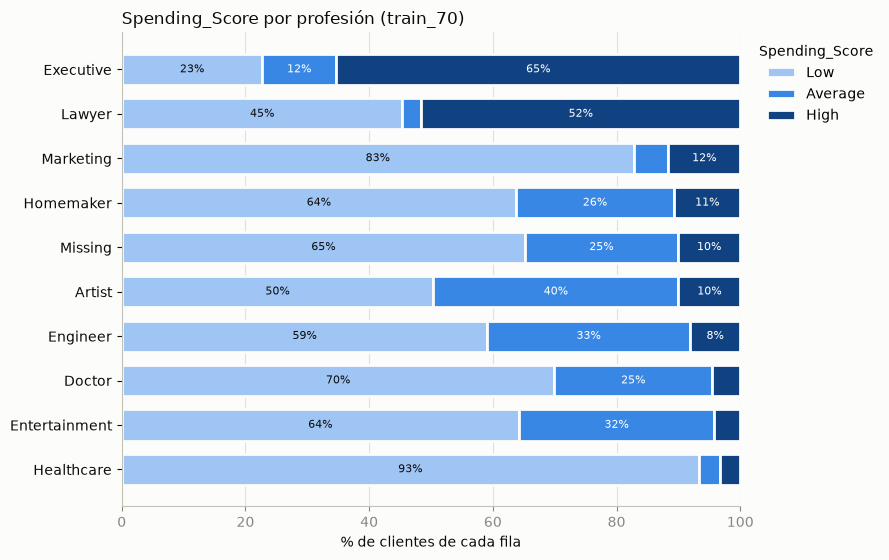

In [7]:
stacked_bars(prof, "Spending_Score por profesión (train_70)", "eda_spending_by_profession.png")

## 4. Spending_Score frente a Graduated

In [8]:
grad = proportions("Graduated", "Spending_Score")
grad

Spending_Score,Low,Average,High,n
Graduated,,,,
Missing,62.3,22.6,15.1,53
No,68.8,17.2,14.0,2104
Yes,55.8,28.4,15.8,3490


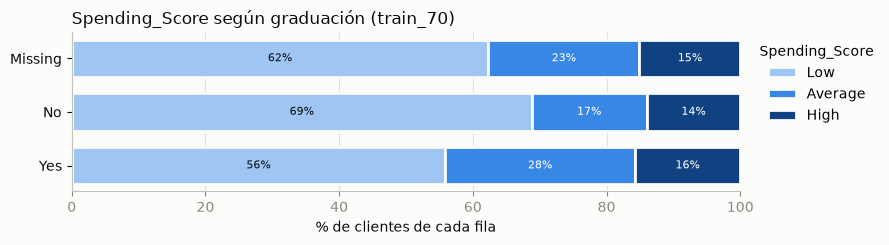

In [9]:
stacked_bars(grad, "Spending_Score según graduación (train_70)", "eda_spending_by_graduated.png")

## 5. Spending_Score frente a Segmentation

Dos lecturas de la misma tabla:
- **Por segmento** (filas = segmento): qué perfil de gasto tiene cada segmento.
- **Por nivel de gasto** (filas = Spending_Score): a qué segmento pertenecen los clientes de cada nivel.

In [10]:
seg_spend = proportions("Segmentation", "Spending_Score")
seg_spend

Spending_Score,Low,Average,High,n
Segmentation,,,,
A,69.1,17.2,13.7,1380
B,48.7,30.7,20.6,1301
C,33.6,45.2,21.2,1379
D,86.8,6.6,6.6,1587


In [11]:
spend_seg = proportions("Spending_Score", "Segmentation")
spend_seg

Segmentation,A,B,C,D,n
Spending_Score,,,,,
Low,27.8,18.5,13.5,40.2,3429
Average,17.4,29.3,45.7,7.7,1364
High,22.1,31.4,34.2,12.3,854


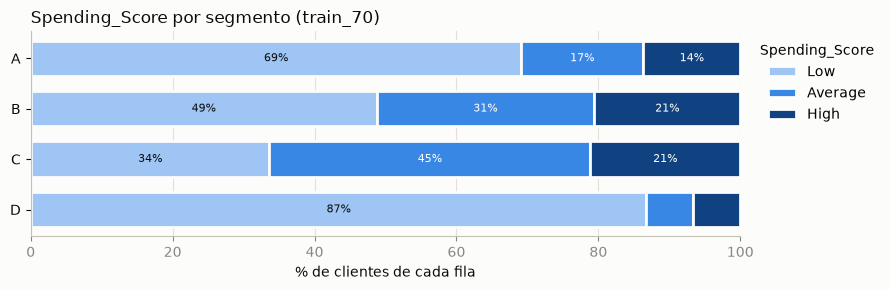

In [12]:
stacked_bars(seg_spend, "Spending_Score por segmento (train_70)", "eda_spending_by_segment.png")

## 6. Ever_Married frente a Segmentation

In [13]:
seg_married = proportions("Segmentation", "Ever_Married")[["Yes", "No", "Missing", "n"]]
seg_married

Ever_Married,Yes,No,Missing,n
Segmentation,,,,
A,57.2,41.1,1.7,1380
B,72.4,25.8,1.8,1301
C,78.5,20.3,1.2,1379
D,28.4,69.4,2.3,1587


In [14]:
married_seg = proportions("Ever_Married", "Segmentation")
married_seg

Segmentation,A,B,C,D,n
Ever_Married,,,,,
Missing,24.2,23.2,16.2,36.4,99
No,24.8,14.7,12.3,48.2,2284
Yes,24.2,28.9,33.2,13.8,3264


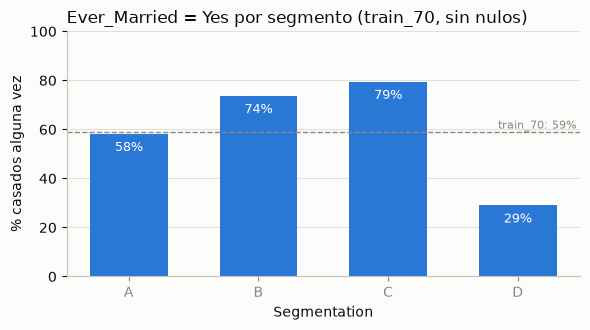

In [15]:
# % married per segment (rows with Ever_Married missing excluded)
known = df.dropna(subset=["Ever_Married"])
pct_married = (known.groupby("Segmentation")["Ever_Married"]
               .apply(lambda s: (s == "Yes").mean() * 100).reindex(SEGMENT_ORDER))
overall = (known["Ever_Married"] == "Yes").mean() * 100

fig, ax = plt.subplots(figsize=(6, 3.4))
bars = ax.bar(pct_married.index, pct_married.values, color="#2a78d6", width=0.6)
ax.axhline(overall, color=MUTED, linewidth=1, linestyle="--")
ax.text(3.45, overall + 1.5, f"train_70: {overall:.0f}%", ha="right", color=MUTED, fontsize=8)
for b, v in zip(bars, pct_married.values):
    ax.text(b.get_x() + b.get_width() / 2, v - 7, f"{v:.0f}%", ha="center", fontsize=9, color="#ffffff")
ax.set_ylim(0, 100)
ax.set_ylabel("% casados alguna vez")
ax.set_xlabel("Segmentation")
ax.yaxis.grid(True, color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.set_title("Ever_Married = Yes por segmento (train_70, sin nulos)", loc="left", color=INK)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "eda_married_by_segment.png"), dpi=120, facecolor=SURFACE)
plt.show()

## 7. Ever_Married frente a Spending_Score (complementario)

No lo pide el issue, pero conecta las dos partes de esta sección: si el gasto y el estado civil están muy ligados, aportan información parecida al modelo.

In [16]:
married_spend = proportions("Ever_Married", "Spending_Score")
married_spend

Spending_Score,Low,Average,High,n
Ever_Married,,,,
Missing,47.5,27.3,25.3,99
No,100.0,0.0,0.0,2284
Yes,33.6,41.0,25.4,3264


In [17]:
# Customers with Ever_Married missing whose Spending_Score is not Low
null_married = df[df["Ever_Married"].isna()]
print(f"Ever_Married nulo: n = {len(null_married)}; "
      f"con gasto Average o High: {(null_married['Spending_Score'] != 'Low').mean() * 100:.1f} %")

Ever_Married nulo: n = 99; con gasto Average o High: 52.5 %


## 8. Fuerza de la asociación (chi-cuadrado y V de Cramér)

Sin filas con nulos en el par analizado. Guía orientativa para V con estas tablas: < 0,1 muy débil; 0,1–0,3 débil a moderada; > 0,3 fuerte.

In [18]:
pairs = [
    ("Spending_Score", "Profession"),
    ("Spending_Score", "Graduated"),
    ("Spending_Score", "Segmentation"),
    ("Ever_Married", "Segmentation"),
    ("Ever_Married", "Spending_Score"),
]
assoc = pd.DataFrame([{"variable_1": a, "variable_2": b, **cramers_v(df[a], df[b])} for a, b in pairs])
assoc["p_valor"] = assoc["p_valor"].map(lambda p: f"{p:.1e}")
assoc["V_Cramer"] = assoc["V_Cramer"].map(lambda v: f"{v:.3f}")
assoc

,variable_1,variable_2,n,chi2,gl,p_valor,V_Cramer
0,Spending_Score,Profession,5558,2165.2,16,0.0e+00,0.441
1,Spending_Score,Graduated,5594,106.5,2,7.4e-24,0.138
2,Spending_Score,Segmentation,5647,1032.7,6,7.4e-220,0.302
3,Ever_Married,Segmentation,5548,925.8,3,2.2e-200,0.408
4,Ever_Married,Spending_Score,5548,2486.4,2,0.0e+00,0.669


**Cómo leer la V de Cramér: ¿por qué Ever_Married–Spending_Score (0,669) supera a cualquier relación con el segmento?**

La V responde a esta pregunta: *si conozco una variable, ¿cuánto puedo adivinar de la otra?* Cuanto más distintas son las filas de la tabla de proporciones, más alta sale.

- **Ever_Married → Spending_Score** (sección 7): de un cliente no casado sabemos su gasto con total seguridad, porque el 100 % es Low. Las filas `No` y `Yes` no se parecen en nada. Es casi una **regla fija**.
- **Ever_Married → Segmentation** (sección 6): de un cliente no casado, la mejor apuesta es D (48,2 %), pero el resto (más de la mitad) son A, B o C. Las filas se solapan; en A casi coinciden (24,8 % frente a 24,2 %). Es solo una **tendencia**.

Consecuencias:
1. Una V alta **entre dos variables de entrada** no las hace más útiles para predecir: indica que se solapan. Para los no casados, `Spending_Score` no añade nada.
2. Ninguna variable por sí sola determina el segmento (V entre 0,30 y 0,44). El modelo tiene que **combinar** varias variables.
3. Una regla del 100 % es poco habitual en datos reales; apunta a cómo se generó o codificó el dataset (ver conclusiones).

## 9. Nulos frente al segmento

¿Los clientes con `Profession`, `Graduated` o `Ever_Married` nulo se reparten entre segmentos igual que el resto? Si no, el hecho de que falte el dato ya da información, y conviene tenerlo en cuenta al decidir la imputación en US-05.

In [19]:
seg_dist = df["Segmentation"].value_counts(normalize=True).reindex(SEGMENT_ORDER) * 100
rows = {"train_70 (todos)": seg_dist}
for c in ["Profession", "Graduated", "Ever_Married"]:
    sub = df.loc[df[c].isna(), "Segmentation"]
    rows[f"{c} nulo (n={len(sub)})"] = sub.value_counts(normalize=True).reindex(SEGMENT_ORDER) * 100
pd.DataFrame(rows).T

Segmentation,A,B,C,D
train_70 (todos),24.4,23.0,24.4,28.1
Profession nulo (n=89),24.7,21.3,12.4,41.6
Graduated nulo (n=53),30.2,18.9,26.4,24.5
Ever_Married nulo (n=99),24.2,23.2,16.2,36.4


## 10. Conclusiones

Todas las cifras salen de las tablas de arriba (`train_70`, 5.647 filas). Son relaciones de dos en dos variables: describen asociación, no causa, y no dicen cuánto aportará cada variable al modelo cuando se combine con las demás.

**¿Qué profesiones concentran gasto alto?**
- Solo dos: **Executive** (65,4 % High) y **Lawyer** (51,6 % High). En el resto de profesiones el gasto alto no pasa del 11,7 % (Marketing).
- Lawyer está muy polarizado: casi no tiene gasto medio (3,0 % Average), o gasta poco (45,4 %) o mucho (51,6 %).
- **Healthcare** es la profesión de menor gasto: 93,3 % Low. Marketing también es mayoritariamente Low (82,7 %).
- Artist (la profesión más frecuente, n = 1.746) y Engineer tienen el mayor peso de gasto medio (39,6 % y 32,7 % Average).
- Asociación moderada-fuerte: V de Cramér = 0,441.

**¿Influye la graduación en el gasto?**
- Poco. Los graduados tienen más gasto medio (28,4 % frente a 17,2 %) y menos bajo (55,8 % frente a 68,8 %), pero el gasto alto es casi igual (15,8 % frente a 14,0 %). V = 0,138, asociación débil.

**¿Cómo se relaciona el gasto con el segmento?**
- **D** es el segmento de gasto bajo: 86,8 % Low. De los clientes con gasto Low, el 40,2 % son D.
- **C** es el de mayor gasto: 45,2 % Average y 21,2 % High (solo 33,6 % Low). **B** tiene el mismo % de High que C (20,6 %), pero más Low (48,7 %).
- **A** tiene un perfil intermedio, más cerca de D: 69,1 % Low.
- Asociación moderada (V = 0,302). El gasto separa bien D de B/C, pero distingue peor B de C.

**¿El estado civil ayuda a distinguir segmentos?**
- Sí, sobre todo para **D**: solo el 29 % de D se ha casado alguna vez (sin contar nulos), frente al 58 % de A, 74 % de B y 79 % de C. De los no casados, el 48,2 % son D.
- **A** está prácticamente en la media de `train_70` (59 %), así que el estado civil no ayuda a reconocerlo. B y C se parecen entre sí (74 % y 79 %).
- Asociación moderada-fuerte: V = 0,408.
- La pregunta del issue sobre **tamaño de familia** (`Family_Size`) corresponde a otra sección del EDA y no se analiza aquí.

**Hallazgo adicional: Ever_Married y Spending_Score están muy ligados**
- El **100 % de los no casados (n = 2.284) tiene gasto Low**: ninguno tiene Average ni High. V = 0,669, la asociación más fuerte de esta sección.
- Consecuencias que conviene comentar con el equipo (no son decisiones):
  - Para los no casados, `Spending_Score` no añade información: ya se sabe que es Low. Las dos variables comparten parte de lo que aportan al modelo.
  - Para la **revisión de fuga de datos** (sección de Brian): una relación tan determinista entre dos variables de entrada parece una regla de cómo se generó o codificó el dataset. No implica fuga hacia `Segmentation`, pero vale la pena mencionarla.
  - Para la **imputación (D-011, aprobada el 13-11)**: D-011 imputa `Ever_Married` con la moda (`Yes`). El 52,5 % de los clientes con `Ever_Married` nulo (n = 99) tiene gasto Average o High; según esta regla serían casados, así que para ellos la moda coincide con lo que dicen los datos. Para el 47,5 % restante (gasto Low) la moda es más dudosa, porque entre los clientes con gasto Low abundan los no casados. Si el equipo decide revisar D-011, imputar teniendo en cuenta `Spending_Score` o añadir un indicador de nulo serían alternativas; afecta a solo 99 filas (1,8 % de `train_70`).

**Nulos frente al segmento**
- Los clientes con `Profession` nulo son más a menudo D (41,6 % frente a 28,1 % en `train_70`) y menos a menudo C (12,4 % frente a 24,4 %). Con `Ever_Married` nulo pasa algo parecido (D 36,4 %, C 16,2 %). Con `Graduated` nulo no se ve un patrón claro.
- Son grupos pequeños (89, 99 y 53 filas), así que hay que tomarlo con cautela.
- Relación con D-011 (aprobada): imputar `Profession` como categoría `Unknown` conserva esta señal, porque los nulos siguen siendo un grupo propio. Imputar `Ever_Married` con la moda la pierde; un indicador de nulo la conservaría.